# Judo: verso un tatami più sicuro

In [1]:
import os
from collections.abc import Callable, Iterable, Sequence
from math import exp
from typing import Any, Literal, Self

import numpy as np
import numpy.typing as npt
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["LM Roman 10", "Latin Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.titlesize": 12,
    "legend.fontsize": 10,
    "figure.figsize": (6, 3.8),
    "savefig.bbox": "tight",
})
from scipy.optimize import minimize
from tabulate import tabulate

# Float NumPY vector
type Array = npt.NDArray[np.float64]

# Load function
type SessionFunction = Callable[[int], float]

# Population name
type Population = Literal["S", "P", "I", "M"]

# Population that can get injured
type InjuryPopulation = Literal["S", "P", "M"]

# Number printed in a table
type Number = int | float | np.integer[Any] | np.floating[Any]

# Table row
type Row = list[str | Number]


def format_table(rows: Iterable[Sequence[Any]], headers: Sequence[str] = ()) -> str:
    """Tabella con i numeri a 4 cifre significative."""
    return tabulate(rows, headers = headers, floatfmt = ".4g")

# Il modello

## Carico e controllo

In [2]:
def periodic_load(t: int) -> float:
    """Carico 1 -> 0.5 -> 0"""
    return ((2 - t) % 3) / 2


def no_prevention(_: int) -> float:
    """Controllo nullo."""
    return 0

## La classe

In [3]:
class Model:
    def __init__(
        self,
        T: int = 50,

        # Zero conditions
        S_0: float = 400,
        P_0: float = 100,
        I_0: float = 0,
        M_0: float = 0,
        F_f_0: float = 0,
        F_p_0: float = 0,

        # Parameters
        alpha: float = 0.8,
        pi: float = 0.4,
        rho: float = 0.05,
        beta_S: float = 0.005,
        beta_P: float = 0.01,
        beta_M: float = 0.05,
        beta_I: float = 0.1,
        gamma_S: float = 0.02,
        gamma_P: float = 0.04,
        gamma_M: float = 0.08,
        A_max: float = 800,

        # Function parameters
        omega_mu: float = 5,
        sigma_mu: float = 0.15,
        sigma_nu: float = 0.15,
        omega_f: float = 0.5,
        omega_p: float = 0.3,
        omega_d: float = 0.2,
        b_lambda: float = 1,
        omega_r: float = 1,
        sigma_r: float = 0.05,

        # Loads
        c_f: SessionFunction = periodic_load,
        c_p: SessionFunction = periodic_load,

        # Prevention
        u: SessionFunction = no_prevention
    ) -> None:
        self.T = T
        self.alpha, self.pi, self.rho = alpha, pi, rho
        self.beta_S, self.beta_P, self.beta_M, self.beta_I = beta_S, beta_P, beta_M, beta_I
        self.gamma_S, self.gamma_P, self.gamma_M = gamma_S, gamma_P, gamma_M
        self.A_max = A_max
        self.omega_mu, self.sigma_mu = omega_mu, sigma_mu
        self.sigma_nu = sigma_nu
        self.omega_f, self.omega_p, self.omega_d, self.b_lambda = omega_f, omega_p, omega_d, b_lambda
        self.omega_r, self.sigma_r = omega_r, sigma_r
        self.c_f, self.c_p = c_f, c_p
        self.u = u

        # variabili di stato per t = 0, ..., T
        self.S: Array = np.zeros(T + 1)
        self.P: Array = np.zeros(T + 1)
        self.I: Array = np.zeros(T + 1)
        self.M: Array = np.zeros(T + 1)
        self.F_f: Array = np.zeros(T + 1)
        self.F_p: Array = np.zeros(T + 1)
        self.S[0], self.P[0], self.I[0], self.M[0] = S_0, P_0, I_0, M_0
        self.F_f[0], self.F_p[0] = F_f_0, F_p_0

        # nuovi infortuni in ogni seduta
        self.injuries: Array = np.zeros(T)

    # Model functions
    def mu(self, x: float) -> float:
        return self.omega_mu * exp(- x ** 2 / (2 * self.sigma_mu ** 2))

    def nu(self, x: float, beta: float) -> float:
        return beta * exp(- (x - 1) ** 2 / (2 * self.sigma_nu ** 2))

    def lam(self, f_f: float, f_p: float, d: float, gamma: float) -> float:
        return gamma / (1 + exp(- self.omega_f * f_f - self.omega_p * f_p - self.omega_d * d + self.b_lambda))

    def r(self, t: int) -> float:
        return 2 * self.omega_r / (1 + exp(self.sigma_r * t))

    def risk(self, t: int) -> float:
        density = (self.S[t] + self.P[t] + self.M[t]) / self.A_max
        return self.lam(self.F_f[t], self.F_p[t], density, 1)

    # Simulation
    def compute(self) -> Self:
        for t in range(self.T):
            S, P, I, M = self.S[t], self.P[t], self.I[t], self.M[t]
            x = t / self.T

            effective_risk = (1 - self.u(t)) * self.risk(t)
            inj_S = self.gamma_S * effective_risk * S
            inj_P = self.gamma_P * effective_risk * P
            inj_M = self.gamma_M * effective_risk * M
            self.injuries[t] = inj_S + inj_P + inj_M

            self.S[t + 1] = S + self.alpha * self.mu(x) - self.nu(x, self.beta_S) * S - inj_S
            self.P[t + 1] = P + (1 - self.alpha) * self.mu(x) - self.nu(x, self.beta_P) * P - inj_P
            self.I[t + 1] = I + self.pi * (inj_S + inj_P + inj_M) - self.rho * I - self.nu(x, self.beta_I) * I
            self.M[t + 1] = M + (1 - self.pi) * (inj_S + inj_P) - self.pi * inj_M + self.rho * I - self.nu(x, self.beta_M) * M
            self.F_f[t + 1] = self.F_f[t] + self.c_f(t) - self.r(t) * self.F_f[t]
            self.F_p[t + 1] = self.F_p[t] + self.c_p(t) - self.r(t) * self.F_p[t]

            if min(self.S[t + 1], self.P[t + 1], self.I[t + 1], self.M[t + 1]) < 0:
                raise ValueError(f"Popolazione negativa al tempo {t + 1}.")
            
        return self

    @property
    def N(self) -> Array:
        return self.S + self.P + self.I + self.M


T = Model().T

## Infortuni e abbandoni di ogni popolazione

In [4]:
POPULATION_NAMES: tuple[Population, ...] = ("S", "P", "I", "M")
INJURY_POPULATIONS: tuple[InjuryPopulation, ...] = ("S", "P", "M")


def injuries_from(model: Model, population: InjuryPopulation) -> Array:
    """Nuovi infortuni della popolazione ("S", "P" o "M") in ogni seduta."""
    gamma: float = getattr(model, "gamma_" + population)
    size: Array = getattr(model, population)

    return np.array([gamma * (1 - model.u(t)) * model.risk(t) * size[t] for t in range(model.T)])


def dropouts_from(model: Model, population: Population) -> Array:
    """Abbandoni della popolazione ("S", "P", "I" o "M") in ogni seduta."""
    beta: float = getattr(model, "beta_" + population)
    size: Array = getattr(model, population)

    return np.array([model.nu(t / model.T, beta) * size[t] for t in range(model.T)])


def dropouts_per_session(model: Model) -> Array:
    """Abbandoni totali in ogni seduta."""
    return np.sum([dropouts_from(model, population) for population in POPULATION_NAMES], axis = 0)


def dropouts(model: Model) -> float:
    """Abbandoni totali in tutto il periodo."""
    return float(np.sum(dropouts_per_session(model)))

# Calibrazione dei parametri

## Requisiti

In [5]:
# la popolazione cresce al massimo del 10%
MAX_GROWTH: float = 0.10

# alla fine resta l'85% del gruppo iniziale
FINAL_POPULATION: float = 0.85

# infortunati e malconci al massimo il 50% del gruppo
MAX_INJURED: float = 0.50

# il picco di infortunati gravi è il 10% del gruppo
PEAK_I: float = 0.10

## Parametri da calibrare

In [6]:
# Parametri da calcolare e loro intervalli (nello stesso ordine)
NAMES: list[str] = ["alpha", "pi", "rho", "beta_S", "beta_P", "beta_M", "beta_I", "gamma_S", "gamma_P", "gamma_M"]
BOUNDS: list[tuple[float, float]] = [
    (0.5, 1), (0.1, 0.6), (0.02, 0.3),
    (0.001, 0.02), (0.001, 0.03), (0.005, 0.4), (0.005, 0.4),
    (0.001, 0.3), (0.001, 0.3), (0.001, 0.3),
]

PRIOR: Array = np.array([getattr(Model(), name) for name in NAMES])

# Ogni valore a priori deve stare dentro il suo intervallo
for name, prior, (low, high) in zip(NAMES, PRIOR, BOUNDS):
    assert low <= prior <= high, f"{name} = {prior} fuori da [{low}, {high}]"

## Funzioni per la calibrazione

- `simulate`: simula il modello a partire dal vettore dei parametri;
- `equality_constraints`: vincoli di uguaglianza (devono valere zero);
- `inequality_constraints`: vincoli di disuguaglianza (devono essere $\geq 0$);
- `distance`: la funzione da minimizzare, cioè la distanza dai valori a priori;
- `calibrate`: chiama `scipy.optimize.minimize`.

In [7]:
def simulate(values: Array, **others: Any) -> Model:
    return Model(**dict(zip(NAMES, values)), **others).compute()


def equality_constraints(values: Array) -> list[float]:
    """Devono valere zero: max(I / N) = 0.10 e N[T] / N[0] = 0.85."""
    model = simulate(values)
    return [max(model.I / model.N) - PEAK_I, model.N[-1] / model.N[0] - FINAL_POPULATION]


def inequality_constraints(values: Array) -> Array:
    model = simulate(values)
    return np.concatenate([
        (1 + MAX_GROWTH) - model.N / model.N[0],
        MAX_INJURED - (model.I + model.M) / model.N,
        np.diff(values[3:7]),   # beta_S <= beta_P <= beta_M <= beta_I
        np.diff(values[7:10]),  # gamma_S <= gamma_P <= gamma_M
    ])


def distance(values: Array) -> float:
    widths = np.array([high - low for low, high in BOUNDS])
    return float(np.sum(((values - PRIOR) / widths) ** 2))


def calibrate() -> Array:
    """Restituisce i valori calibrati, nell'ordine di NAMES."""
    result = minimize(
        distance, PRIOR,
        bounds = BOUNDS,
        # gli stub di scipy prevedono vincoli con un solo valore, ma minimize accetta anche vettori di vincoli
        constraints = [
            {"type": "eq", "fun": equality_constraints},     # type: ignore[list-item]
            {"type": "ineq", "fun": inequality_constraints}, # type: ignore[list-item]
        ],
    )
    if not result.success:
        raise RuntimeError(f"Calibrazione non riuscita: {result.message}")

    return result.x

## Calibrazione

In [8]:
calibrated_values: Array = calibrate()

print(format_table(
    zip(NAMES, PRIOR, calibrated_values),
    headers = ["Parametro", "Valore a priori", "Valore calibrato"]
))

Parametro      Valore a priori    Valore calibrato
-----------  -----------------  ------------------
alpha                    0.8              0.8
pi                       0.4              0.3974
rho                      0.05             0.05354
beta_S                   0.005            0.005056
beta_P                   0.01             0.01002
beta_M                   0.05             0.05883
beta_I                   0.1              0.1045
gamma_S                  0.02             0.02126
gamma_P                  0.04             0.03999
gamma_M                  0.08             0.07778


# Grafici

In [9]:
SIMULATION_DIR: str = os.path.join("..", "tesi", "images", "simulazione")
CONTROL_DIR: str = os.path.join("..", "tesi", "images", "controllo")
os.makedirs(SIMULATION_DIR, exist_ok = True)
os.makedirs(CONTROL_DIR, exist_ok = True)

POPULATIONS: tuple[tuple[Population, str, str], ...] = (("S", "#009933", "Sani"), ("P", "#336699", "Pregressi"),
               ("I", "#EE0000", "Infortunati"), ("M", "#FFAD00", "Malconci"))


def save_plot(
        name: str,
        title: str,
        y_label: str,
        folder: str = SIMULATION_DIR,
        x_label: str = r"$t$",
        legend_position: str = "best",
        legend_below: bool = False
    ) -> None:
    plt.xlim(0, T)
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)
    plt.grid(True, linestyle = "--", alpha = 0.6)

    if legend_below:
        plt.legend(loc = "upper center", bbox_to_anchor = (0.5, -0.15), ncol = 2, frameon = False)
    else:
        plt.legend(loc = legend_position)

    plt.tight_layout()
    plt.savefig(os.path.join(folder, name + ".pdf"), dpi = 300)
    plt.show()
    plt.close()

# Simulazione con i parametri calibrati

In [10]:
calibrated_model: Model = simulate(calibrated_values)
N: Array = calibrated_model.N

## Le funzioni del modello

In [11]:
print("===== Funzioni =====")

m: Model = calibrated_model
density: Array = (m.S + m.P + m.M) / m.A_max

print(format_table([
    ["Ingressi", "totali", sum(m.mu(t / T) for t in range(T))],
    ["Ingressi", "prime 15 sedute", sum(m.mu(t / T) for t in range(15))],
    ["Abbandoni nu / beta", "al 25%", m.nu(0.25, 1)],
    ["Abbandoni nu / beta", "al 50%", m.nu(0.5, 1)],
    ["Abbandoni nu / beta", "al 75%", m.nu(0.75, 1)],
    ["Abbandoni nu / beta", "alla fine", m.nu(1, 1)],
    ["Densità", "inizio", density[0]],
    ["Densità", "fine", min(density)],
    ["Rischio relativo", "inizio", m.risk(0)],
    ["Rischio relativo", "fine", m.risk(T)],
    ["Recupero", "al 25%", m.r(round(T / 4))],
    ["Recupero", "al 50%", m.r(round(T / 2))],
    ["Recupero", "al 75%", m.r(round(3 * T / 4))],
    ["Recupero", "alla fine", m.r(T)],
    ["Fatica", "prime 20 sedute (max)", max(m.F_f[:21])],  # sedute da 0 a 20
    ["Fatica", "alla fine", m.F_f[T]]
]))

===== Funzioni =====
-------------------  ---------------------  ----------
Ingressi             totali                 49.5
Ingressi             prime 15 sedute        47.01
Abbandoni nu / beta  al 25%                  3.727e-06
Abbandoni nu / beta  al 50%                  0.003866
Abbandoni nu / beta  al 75%                  0.2494
Abbandoni nu / beta  alla fine               1
Densità              inizio                  0.625
Densità              fine                    0.4831
Rischio relativo     inizio                  0.2942
Rischio relativo     fine                    0.7918
Recupero             al 25%                  0.7087
Recupero             al 50%                  0.4454
Recupero             al 75%                  0.2602
Recupero             alla fine               0.1517
Fatica               prime 20 sedute (max)   1.155
Fatica               alla fine               2.799
-------------------  ---------------------  ----------


## Fatica e recupero

Confronto tra il recupero scelto ($\sigma_r = 0.05$) e un recupero che decade più in fretta ($\sigma_r = 0.2$).

In [12]:
print("\n===== Recupero con sigma_r = 0.2 =====")

fast_decay_model: Model = simulate(calibrated_values, sigma_r = 0.2)

print(format_table([
    ["Fatica", "alla fine", fast_decay_model.F_f[T]],
    ["Rischio relativo", "50%", fast_decay_model.risk(round(T / 2))],
    ["Infortuni", "totali", sum(fast_decay_model.injuries)]
]))


===== Recupero con sigma_r = 0.2 =====
----------------  ---------  --------
Fatica            alla fine   17.98
Rischio relativo  50%          0.9814
Infortuni         totali     709.4
----------------  ---------  --------


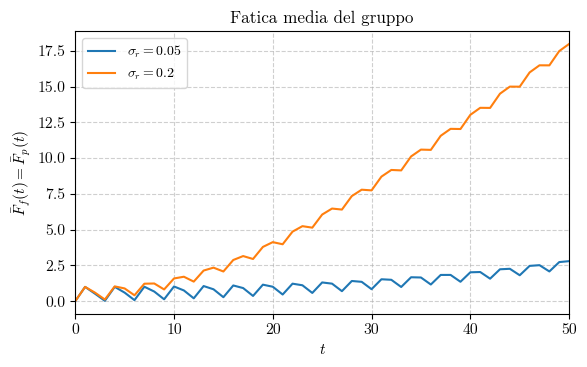

In [13]:
# Fatica
plt.plot(calibrated_model.F_f, label = r"$\sigma_r = 0.05$")
plt.plot(fast_decay_model.F_f, label = r"$\sigma_r = 0.2$")

save_plot("fatica", "Fatica media del gruppo", r"$\bar{F}_f(t) = \bar{F}_p(t)$")

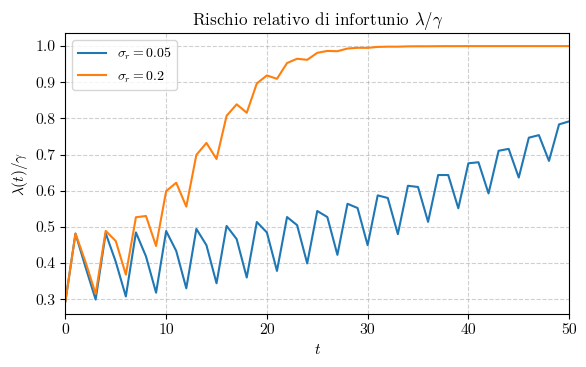

In [14]:
# Rischio relativo
plt.plot([calibrated_model.risk(t) for t in range(T + 1)], label = r"$\sigma_r = 0.05$")
plt.plot([fast_decay_model.risk(t) for t in range(T + 1)], label = r"$\sigma_r = 0.2$")

save_plot("rischio", r"Rischio relativo di infortunio $\lambda / \gamma$", r"$\lambda(t) / \gamma$")

## Valori a priori VS parametri calibrati

Riassunto della simulazione con i valori a priori e con quelli calibrati.

In [15]:
def summary(model: Model) -> list[Row]:
    """Righe della tabella riassuntiva di una simulazione."""
    N = model.N
    return [
        ["Popolazione", "max(N) / N[0]", max(N) / N[0]],
        ["Popolazione", "N[-1] / N[0]", N[-1] / N[0]],
        ["Popolazione", "finale", N[-1]],
        ["Infortunati", "picco", max(model.I)],
        ["Infortunati", "max(I) / N", max(model.I / N)],
        ["Malconci", "picco", max(model.M)],
        ["Malconci", "max(M) / N", max(model.M / N)],
        ["Massimo di (I + M) / N", "", max((model.I + model.M) / N)],
        ["Infortuni", "totali", sum(model.injuries)]
    ]

In [16]:
print("\n===== Valori a priori =====")

print(format_table(summary(simulate(PRIOR))))


===== Valori a priori =====
----------------------  -------------  --------
Popolazione             max(N) / N[0]    1.099
Popolazione             N[-1] / N[0]     0.8728
Popolazione             finale         436.4
Infortunati             picco           53.48
Infortunati             max(I) / N       0.1018
Malconci                picco          126
Malconci                max(M) / N       0.2507
Massimo di (I + M) / N                   0.3496
Infortuni               totali         417.3
----------------------  -------------  --------


In [17]:
print("\n===== Riassunto parametri calibrati =====")

m = calibrated_model
max_risk: float = max(m.risk(t) for t in range(T + 1))

table: list[Row] = summary(m) + [
    ["Permanenza media in I", "1 / rho", 1 / m.rho],
    ["Rischio massimo a seduta", "S", m.gamma_S * max_risk],
    ["Rischio massimo a seduta", "P", m.gamma_P * max_risk],
    ["Rischio massimo a seduta", "M", m.gamma_M * max_risk]
]

print(format_table(table))


===== Riassunto parametri calibrati =====
------------------------  -------------  ---------
Popolazione               max(N) / N[0]    1.099
Popolazione               N[-1] / N[0]     0.85
Popolazione               finale         425
Infortunati               picco           52.5
Infortunati               max(I) / N       0.1
Malconci                  picco          131.4
Malconci                  max(M) / N       0.2588
Massimo di (I + M) / N                     0.3568
Infortuni                 totali         428.1
Permanenza media in I     1 / rho         18.68
Rischio massimo a seduta  S                0.01683
Rischio massimo a seduta  P                0.03166
Rischio massimo a seduta  M                0.06159
------------------------  -------------  ---------


## Popolazione

In [18]:
print("\n===== Popolazione totale =====")

table = []
for p in [0, 0.25, 0.5, 0.75, 1]:
    t = round(T * p)
    table.append([f"{p:.0%}", N[t], N[t] / N[0]])

table.append(["Massimo", max(N), max(N / N[0])])
table.append(["Minimo", min(N), min(N / N[0])])

print(format_table(table, headers = ["", "N[t]", "N[t] / N[0]"]))


===== Popolazione totale =====
           N[t]    N[t] / N[0]
-------  ------  -------------
0%        500            1
25%       543.6          1.087
50%       549.4          1.099
75%       536.6          1.073
100%      425            0.85
Massimo   549.4          1.099
Minimo    425            0.85


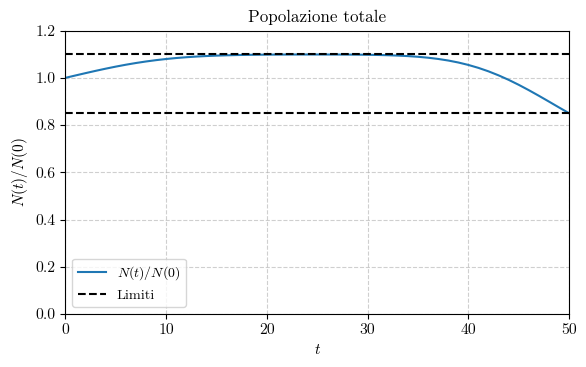

In [19]:
plt.plot(N / N[0], label = r"$N(t) / N(0)$")
plt.ylim((0, 1.2))
plt.axhline(1 + MAX_GROWTH, color = "black", linestyle = "--", label = "Limiti")
plt.axhline(FINAL_POPULATION, color = "black", linestyle = "--")

save_plot("popolazione_totale", "Popolazione totale", r"$N(t) / N(0)$")

## Le quattro popolazioni

In [20]:
print("\n===== Popolazioni =====")

m = calibrated_model

table = []
for t in (10, 20, 30, 40, T):
    table.append([t, m.S[t], m.P[t], m.I[t], m.M[t], (m.I[t] + m.M[t]) / N[t]])

print(format_table(table, headers = ["Seduta", "S", "P", "I", "M", "(I + M) / N"]))


print("\n===== Picchi =====")

IM_above_SP: npt.NDArray[np.intp] = np.where(m.I + m.M > m.S + m.P)[0]
M_above_S: npt.NDArray[np.intp] = np.where(m.M > m.S)[0]

print(format_table([
    ["Picco di I", "seduta", m.I.argmax()],
    ["Picco di M", "seduta", m.M.argmax()],
    ["Picco di I / N", "seduta", (m.I / N).argmax()],
    ["I + M supera S + P", "sedute", ", ".join(map(str, IM_above_SP)) or "mai"],
    ["M supera S", "sedute", ", ".join(map(str, M_above_S)) or "mai"]
]))


===== Popolazioni =====
  Seduta      S      P      I       M    (I + M) / N
--------  -----  -----  -----  ------  -------------
      10  398.8  92.89  16.57   31.62        0.08927
      20  370.1  79.48  31.01   68.49        0.1812
      30  333.5  65.23  44.36  105.7         0.2735
      40  293.2  51.09  51.88  131.1         0.3471
      50  243.1  35.66  38.49  107.8         0.3442

===== Picchi =====
------------------  ------  ---
Picco di I          seduta  39
Picco di M          seduta  41
Picco di I / N      seduta  42
I + M supera S + P  sedute  mai
M supera S          sedute  mai
------------------  ------  ---


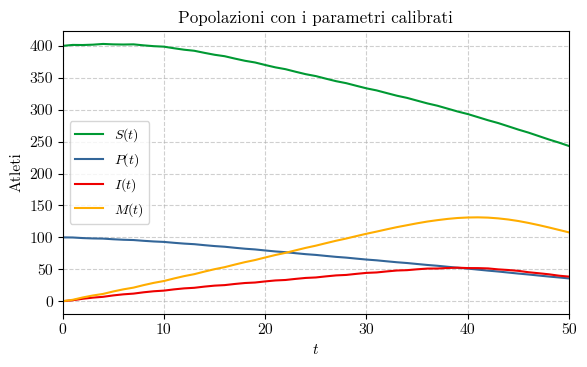

In [21]:
# Le quattro popolazioni, con i colori del diagramma dei flussi
for population, color, _ in POPULATIONS:
    plt.plot(getattr(calibrated_model, population), color = color, label = rf"${population}(t)$")

save_plot("popolazioni", "Popolazioni con i parametri calibrati", "Atleti")

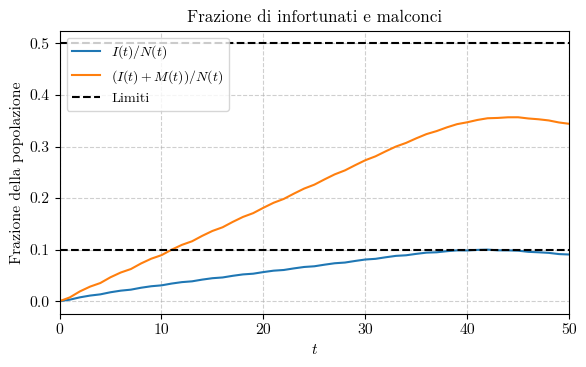

In [22]:
# Frazioni di infortunati
plt.plot(calibrated_model.I / N, label = r"$I(t) / N(t)$")
plt.plot((calibrated_model.I + calibrated_model.M) / N, label = r"$(I(t) + M(t)) / N(t)$")

plt.axhline(PEAK_I, color = "black", linestyle = "--", label = "Limiti")
plt.axhline(MAX_INJURED, color = "black", linestyle = "--")

save_plot("frazione_infortunati", "Frazione di infortunati e malconci", "Frazione della popolazione",
          legend_position = "upper left")

## Infortuni

In [23]:
print("\n===== Infortuni =====")

m = calibrated_model
total_injuries: float = sum(m.injuries)
attendances: float = sum(m.S[:T] + m.P[:T] + m.M[:T])

table = [
    ["Per seduta", "media", total_injuries / T],
    ["Per seduta", "prima seduta", m.injuries[0]],
    ["Per seduta", "massimo", max(m.injuries)],
    ["Per seduta", "seduta del massimo", m.injuries.argmax()],
    ["Totali", "prima metà", sum(m.injuries[:T // 2])],
    ["Totali", "seconda metà", sum(m.injuries[T // 2:])],
    ["Totali", "gravi", m.pi * total_injuries],
    ["Totali", "lievi", (1 - m.pi) * total_injuries],
]
for population in INJURY_POPULATIONS:
    injuries: float = sum(injuries_from(m, population))
    table.append([f"Da {population}", "numero", injuries])
    table.append([f"Da {population}", "frazione", injuries / total_injuries])
table.append(["Ogni 1000 presenze", "", 1000 * total_injuries / attendances])

print(format_table(table))


===== Infortuni =====
------------------  ------------------  --------
Per seduta          media                 8.562
Per seduta          prima seduta          3.679
Per seduta          massimo              12.71
Per seduta          seduta del massimo   43
Totali              prima metà          158.4
Totali              seconda metà        269.7
Totali              gravi               170.1
Totali              lievi               258
Da S                numero              184.2
Da S                frazione              0.4302
Da P                numero               70.2
Da P                frazione              0.164
Da M                numero              173.7
Da M                frazione              0.4058
Ogni 1000 presenze                       17.25
------------------  ------------------  --------


## Abbandoni

In [24]:
print("\n===== Abbandoni =====")

dropouts_by_population: dict[Population, float] = {
    population: sum(dropouts_from(calibrated_model, population)) for population in POPULATION_NAMES
}
total_dropouts: float = sum(dropouts_by_population.values())

table = [["Totali", "", total_dropouts]]
for population, value in dropouts_by_population.items():
    table.append([f"Da {population}", "", value])
table.append(["Da I + M", "frazione", (dropouts_by_population["I"] + dropouts_by_population["M"]) / total_dropouts])

print(format_table(table))


===== Abbandoni =====
--------  --------  --------
Totali              124.5
Da S                 12.35
Da P                  4.038
Da I                 43.66
Da M                 64.45
Da I + M  frazione    0.8683
--------  --------  --------


# Modello con controllo

## La strategia di prevenzione

In [25]:
# prevenzione nel giorno di randori: nel giorno di tecnica è la metà, nel giorno di riposo è nulla
U_BASE: float = 0.6


def prevention(t: int) -> float:
    """Prevenzione proporzionale al carico: u(t) = U_BASE * c(t)."""
    return U_BASE * periodic_load(t)

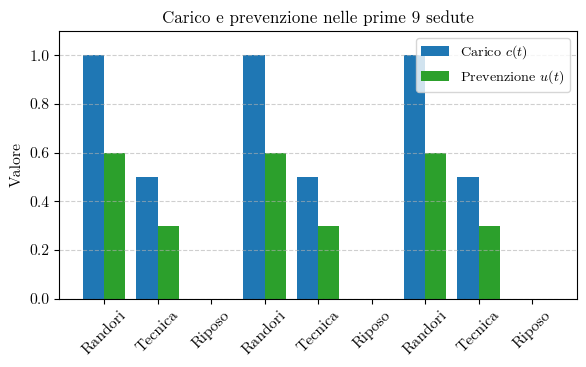

In [26]:
# Carico e prevenzione nelle prime 9 sedute, per leggere bene il ciclo
sessions: range = range(9)

plt.bar([t - 0.2 for t in sessions], [periodic_load(t) for t in sessions], width = 0.4, label = r"Carico $c(t)$")
plt.bar([t + 0.2 for t in sessions], [prevention(t) for t in sessions], width = 0.4, color = "tab:green", label = r"Prevenzione $u(t)$")

plt.xticks(sessions, ["Randori", "Tecnica", "Riposo"] * (len(sessions) // 3), rotation = 45)
plt.ylim(0, 1.1)
plt.ylabel("Valore")
plt.title(f"Carico e prevenzione nelle prime {len(sessions)} sedute")
plt.grid(True, axis = "y", linestyle = "--", alpha = 0.6)
plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(CONTROL_DIR, "strategia.pdf"), dpi = 300)
plt.show()
plt.close()

## Simulazioni senza e con prevenzione

In [27]:
no_control_model: Model = simulate(calibrated_values)
control_model: Model = simulate(calibrated_values, u = prevention)

# nome e colore di ogni simulazione nei grafici di confronto
simulations: dict[str, tuple[Model, str]] = {"Senza prevenzione": (no_control_model, "grey"), "Con prevenzione": (control_model, "tab:green")}


def compare[Q](quantity: Callable[[Model], Q]) -> list[Q]:
    """Applica quantity alle due simulazioni: [senza prevenzione, con prevenzione]."""
    return [quantity(no_control_model), quantity(control_model)]


def comparison_row(name: str, quantity: Callable[[Model], float]) -> Row:
    """Riga di confronto: valore senza e con prevenzione e variazione percentuale."""
    a, b = compare(quantity)
    return [name, a, b, f"{(b - a) / a:+.1%}"]

## Confronto generale

In [28]:
print("\n===== Prevenzione =====")

print(format_table([
    ["Randori", U_BASE],
    ["Tecnica", U_BASE / 2],
    ["Riposo", 0],
    ["Media", np.mean([prevention(t) for t in range(T)])]
], headers = ["Seduta", "u(t)"]))


print("\n===== Confronto =====")

rows: list[Row] = [
    comparison_row("Infortuni totali", lambda m: sum(m.injuries)),
    comparison_row("Infortuni gravi", lambda m: m.pi * sum(m.injuries)),
    comparison_row("Abbandoni totali", dropouts),
    comparison_row("Picco di I", lambda m: max(m.I)),
    comparison_row("Picco di M", lambda m: max(m.M)),
    comparison_row("Atleti alla fine", lambda m: m.N[-1]),
    comparison_row("Sani alla fine", lambda m: m.S[-1]),
]

print(format_table(rows, headers = ["", "Senza prevenzione", "Con prevenzione", "Variazione"]))


===== Prevenzione =====
Seduta      u(t)
--------  ------
Randori    0.6
Tecnica    0.3
Riposo     0
Media      0.306

===== Confronto =====
                    Senza prevenzione    Con prevenzione  Variazione
----------------  -------------------  -----------------  ------------
Infortuni totali                428.1             296     -30.9%
Infortuni gravi                 170.1             117.6   -30.9%
Abbandoni totali                124.5             101.6   -18.4%
Picco di I                       52.5              37.14  -29.3%
Picco di M                      131.4             105.9   -19.4%
Atleti alla fine                425               447.9   +5.4%
Sani alla fine                  243.1             284.1   +16.9%


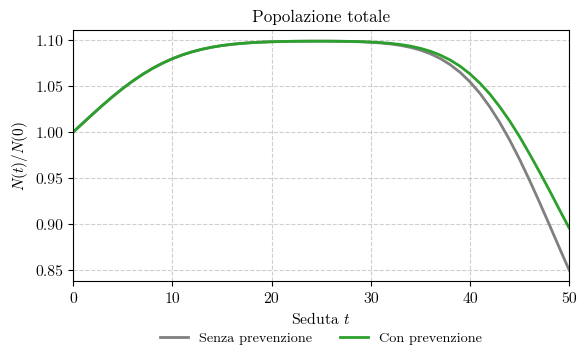

In [29]:
for name, (model, color) in simulations.items():
    plt.plot(model.N / model.N[0], color = color, linewidth = 2, label = name)

save_plot("popolazione_totale", "Popolazione totale", r"$N(t) / N(0)$",
          folder = CONTROL_DIR, x_label = r"Seduta $t$", legend_below = True)

## Infortuni

In [30]:
print("\n===== Infortuni =====")

print(format_table([
    ["Da S", *compare(lambda m: sum(injuries_from(m, "S")))],
    ["Da P", *compare(lambda m: sum(injuries_from(m, "P")))],
    ["Da M", *compare(lambda m: sum(injuries_from(m, "M")))],
    ["Prima metà", *compare(lambda m: sum(m.injuries[:T // 2]))],
    ["Seconda metà", *compare(lambda m: sum(m.injuries[T // 2:]))]
], headers = ["", "Senza prevenzione", "Con prevenzione"]))


print("\n===== Infortuni per tipo di seduta =====")

table = []
for day, load in (("Randori", 1), ("Tecnica", 0.5), ("Riposo", 0)):
    table.append(comparison_row(day, lambda m: sum(m.injuries[t] for t in range(T) if periodic_load(t) == load)))

print(format_table(table, headers = ["Seduta", "Senza prevenzione", "Con prevenzione", "Variazione"]))


===== Infortuni =====
                Senza prevenzione    Con prevenzione
------------  -------------------  -----------------
Da S                        184.2             141.5
Da P                         70.2              56.84
Da M                        173.7              97.71
Prima metà                  158.4             110.5
Seconda metà                269.7             185.6

===== Infortuni per tipo di seduta =====
Seduta      Senza prevenzione    Con prevenzione  Variazione
--------  -------------------  -----------------  ------------
Randori                 122.2              47.29  -61.3%
Tecnica                 162.1             109.8   -32.2%
Riposo                  143.8             138.9   -3.4%


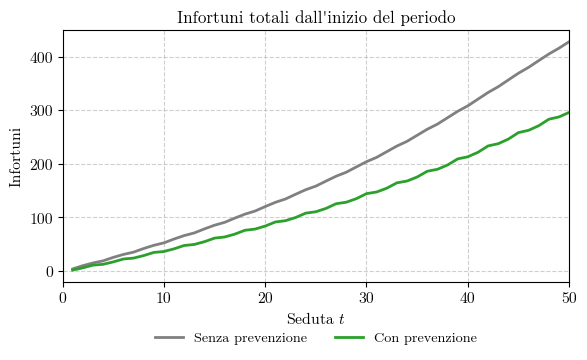

In [31]:
for name, (model, color) in simulations.items():
    plt.plot(range(1, T + 1), np.cumsum(model.injuries), color = color, linewidth = 2, label = name)

save_plot("infortuni_cumulati", "Infortuni totali dall'inizio del periodo", "Infortuni",
          folder = CONTROL_DIR, x_label = r"Seduta $t$", legend_below = True)

## Abbandoni

In [32]:
print("\n===== Abbandoni =====")

print(format_table(
    [[f"Da {population}", *compare(lambda m: sum(dropouts_from(m, population)))] for population in POPULATION_NAMES],
    headers = ["", "Senza prevenzione", "Con prevenzione"]
))


===== Abbandoni =====
        Senza prevenzione    Con prevenzione
----  -------------------  -----------------
Da S               12.35              14.01
Da P                4.038              5.115
Da I               43.66              30.16
Da M               64.45              52.32


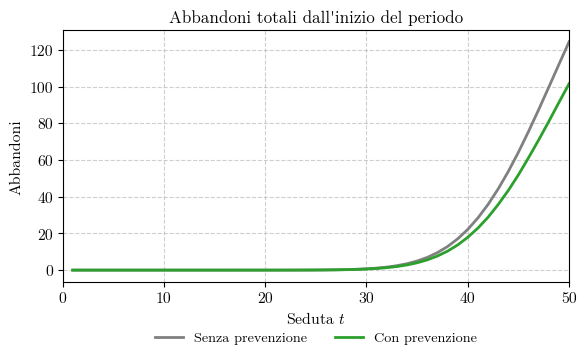

In [33]:
for name, (model, color) in simulations.items():
    plt.plot(range(1, T + 1), np.cumsum(dropouts_per_session(model)), color = color, linewidth = 2, label = name)

save_plot("abbandoni_cumulati", "Abbandoni totali dall'inizio del periodo", "Abbandoni",
          folder = CONTROL_DIR, x_label = r"Seduta $t$", legend_below = True)

## Le quattro popolazioni

In [34]:
print("\n===== Infortunati e malconci =====")

print(format_table([
    ["Picco di I / N", *compare(lambda m: max(m.I / m.N))],
    ["Seduta del picco di I / N", *compare(lambda m: (m.I / m.N).argmax())],
    ["Seduta del picco di I", *compare(lambda m: m.I.argmax())],
    ["Seduta del picco di M", *compare(lambda m: m.M.argmax())],
    ["Massimo di (I + M) / N", *compare(lambda m: max((m.I + m.M) / m.N))],
    ["(I + M) / N alla fine", *compare(lambda m: (m.I[-1] + m.M[-1]) / m.N[-1])]
], headers = ["", "Senza prevenzione", "Con prevenzione"]))


print("\n===== Popolazioni =====")

table = []
for population, _, _ in POPULATIONS:
    a, b = compare(lambda m: getattr(m, population))
    difference = b - a
    k = abs(difference).argmax()
    table.append([population, a[-1], b[-1], max(a), a.argmax(), max(b), b.argmax(), difference[k], k])

print(format_table(table, headers = [
    "", "Fine senza", "Fine con", "Max senza", "Seduta", "Max con", "Seduta", "Differenza massima", "Seduta"
]))


===== Infortunati e malconci =====
                             Senza prevenzione    Con prevenzione
-------------------------  -------------------  -----------------
Picco di I / N                          0.1               0.06983
Seduta del picco di I / N              42                42
Seduta del picco di I                  39                39
Seduta del picco di M                  41                42
Massimo di (I + M) / N                  0.3568            0.2742
(I + M) / N alla fine                   0.3442            0.2586

===== Popolazioni =====
      Fine senza    Fine con    Max senza    Seduta    Max con    Seduta    Differenza massima    Seduta
--  ------------  ----------  -----------  --------  ---------  --------  --------------------  --------
S         243.1       284.1         403           4     409.3          7                 41.05        50
P          35.66       47.95        100           0     100.5          1                 12.44        44
I          

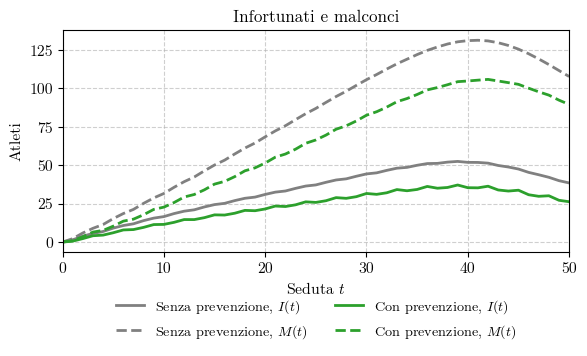

In [35]:
# Infortunati e malconci, senza e con prevenzione
for name, (model, color) in simulations.items():
    plt.plot(model.I, color = color, linewidth = 2, label = name + r", $I(t)$")
    plt.plot(model.M, color = color, linewidth = 2, linestyle = "--", label = name + r", $M(t)$")

save_plot("infortunati", "Infortunati e malconci", "Atleti",
          folder = CONTROL_DIR, x_label = r"Seduta $t$", legend_below = True)

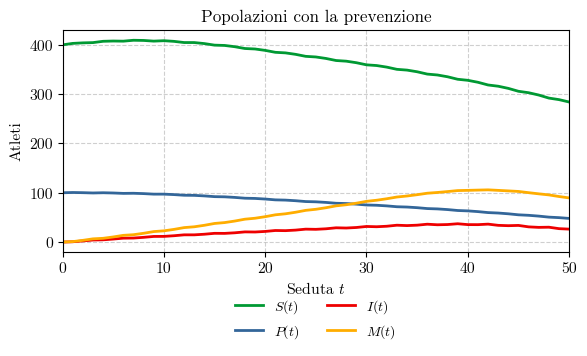

In [36]:
# Le quattro popolazioni con la prevenzione
for population, color, _ in POPULATIONS:
    plt.plot(getattr(control_model, population), color = color, linewidth = 2, label = rf"${population}(t)$")

save_plot("popolazioni", "Popolazioni con la prevenzione", "Atleti",
          folder = CONTROL_DIR, x_label = r"Seduta $t$", legend_below = True)

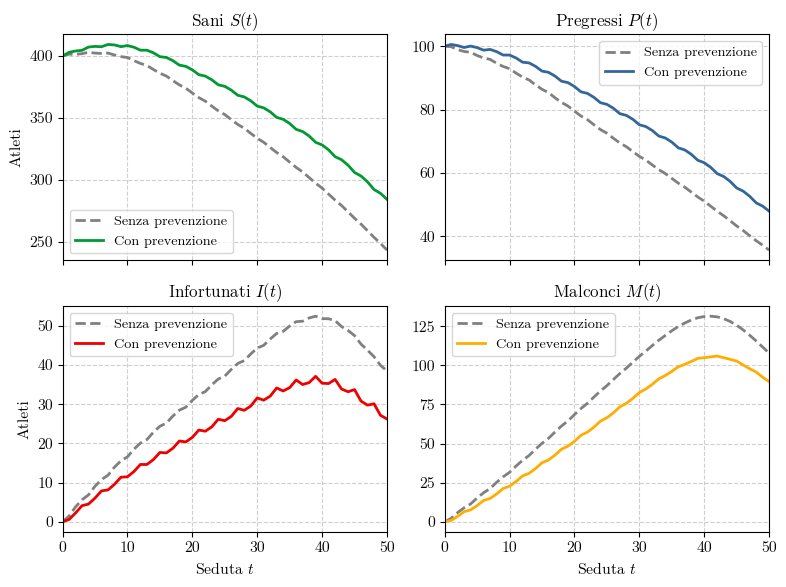

In [37]:
# Ogni popolazione con e senza prevenzione
fig, axes = plt.subplots(2, 2, figsize = (8, 6), sharex = True)

for ax, (population, color, title) in zip(axes.flat, POPULATIONS):
    ax.plot(getattr(no_control_model, population), color = "grey", linewidth = 2, linestyle = "--", label = "Senza prevenzione")
    ax.plot(getattr(control_model, population), color = color, linewidth = 2, label = "Con prevenzione")
    ax.set_title(rf"{title} ${population}(t)$")
    ax.set_xlim(0, T)
    ax.grid(True, linestyle = "--", alpha = 0.6)
    ax.legend()

for ax in axes[1]:
    ax.set_xlabel(r"Seduta $t$")
for ax in axes[:, 0]:
    ax.set_ylabel("Atleti")

plt.tight_layout()
plt.savefig(os.path.join(CONTROL_DIR, "confronto_popolazioni.pdf"), dpi = 300)
plt.show()
plt.close()

## Intensità della prevenzione

In [38]:
print("\n===== Intensità della prevenzione =====")

table = []
for level in (0, 0.2, 0.4, 0.6, 0.8, 1):
    model = simulate(calibrated_values, u = lambda t, level = level: level * periodic_load(t))
    table.append([
        level,
        np.mean([model.u(t) for t in range(T)]),
        sum(model.injuries),
        dropouts(model),
        model.N[-1] / model.N[0]
    ])

print(format_table(table, headers = ["u randori", "u medio", "Infortuni", "Abbandoni", "N finale / N(0)"]))


===== Intensità della prevenzione =====
  u randori    u medio    Infortuni    Abbandoni    N finale / N(0)
-----------  ---------  -----------  -----------  -----------------
        0        0            428.1       124.5              0.85
        0.2      0.102        383.7       117.2              0.8647
        0.4      0.204        339.6       109.5              0.8799
        0.6      0.306        296         101.6              0.8958
        0.8      0.408        253          93.36             0.9123
        1        0.51         210.7        84.78             0.9294


## Riepilogo per le conclusioni

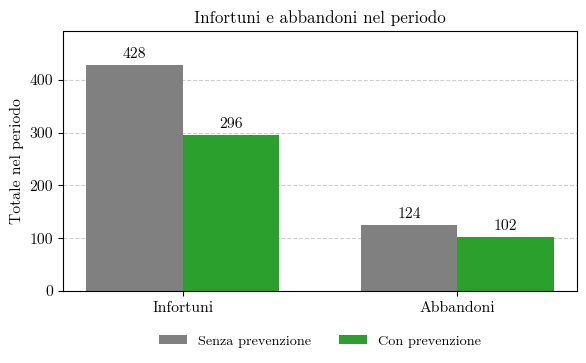

In [39]:
CONCLUSIONS_DIR: str = os.path.join("..", "tesi", "images", "conclusioni")
os.makedirs(CONCLUSIONS_DIR, exist_ok = True)

# Infortuni e abbandoni totali, senza e con prevenzione
quantities: dict[str, list[float]] = {
    "Infortuni": compare(lambda m: float(sum(m.injuries))),
    "Abbandoni": compare(dropouts)
}
positions: Array = np.arange(len(quantities))
width: float = 0.35

fig, ax = plt.subplots(figsize = (6, 3.8))
for i, (name, (_, color)) in enumerate(simulations.items()):
    values: list[float] = [pair[i] for pair in quantities.values()]
    bars = ax.bar(positions + (i - 0.5) * width, values, width, color = color, label = name)
    ax.bar_label(bars, labels = [f"{value:.0f}" for value in values], padding = 3)

ax.set_xticks(positions, list(quantities))
ax.set_ylabel("Totale nel periodo")
ax.set_title("Infortuni e abbandoni nel periodo")
ax.set_ylim(0, 1.15 * max(max(pair) for pair in quantities.values()))
ax.grid(True, axis = "y", linestyle = "--", alpha = 0.6)
ax.set_axisbelow(True)
ax.legend(loc = "upper center", bbox_to_anchor = (0.5, -0.12), ncol = 2, frameon = False)

plt.tight_layout()
plt.savefig(os.path.join(CONCLUSIONS_DIR, "riepilogo.pdf"), dpi = 300)
plt.show()
plt.close()